## Import libraries and load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

df = pd.read_csv("healthcare_patients_raw.csv")
df.head()

,age,gender,bmi,blood_pressure,heart_rate,hospital_days,treatment_cost,smoker,diabetes,follow_up
0,24,Male,29.6,122.3,84.0,2,2633.86,Yes,No,No
1,70,Male,26.5,127.0,87.0,6,5400.39,Yes,No,No
2,62,Female,17.9,135.4,75.9,6,4969.38,Yes,No,No
3,47,Male,31.9,144.7,83.9,7,5433.27,No,No,Yes
4,47,Female,24.1,132.9,54.7,4,5089.42,Yes,No,No


## Initial inspection and data cleaning

In [2]:
print("First five rows:")
display(df.head())
print("Last five rows:")
display(df.tail())
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print("\nData types:")
print(df.dtypes)
print("\nMissing values:")
print(df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())

# Remove exact duplicate records and fill missing numeric values with medians.
df = df.drop_duplicates().copy()
for col in ["bmi", "heart_rate"]:
    df[col] = df[col].fillna(df[col].median())

categorical = df.select_dtypes(include=["object"]).columns.tolist()
numerical = df.select_dtypes(include=np.number).columns.tolist()
print("Categorical:", categorical)
print("Numerical:", numerical)
print("Cleaned shape:", df.shape)
print(df.isna().sum())

First five rows:


,age,gender,bmi,blood_pressure,heart_rate,hospital_days,treatment_cost,smoker,diabetes,follow_up
0,24,Male,29.6,122.3,84.0,2,2633.86,Yes,No,No
1,70,Male,26.5,127.0,87.0,6,5400.39,Yes,No,No
2,62,Female,17.9,135.4,75.9,6,4969.38,Yes,No,No
3,47,Male,31.9,144.7,83.9,7,5433.27,No,No,Yes
4,47,Female,24.1,132.9,54.7,4,5089.42,Yes,No,No


Last five rows:


,age,gender,bmi,blood_pressure,heart_rate,hospital_days,treatment_cost,smoker,diabetes,follow_up
296,75,Male,31.1,151.2,74.7,7,6189.01,Yes,No,No
297,47,Male,21.4,120.6,57.9,4,3666.88,No,No,No
298,37,Female,21.5,129.3,61.3,6,5548.44,No,No,Yes
299,19,Male,29.5,120.5,82.4,4,3649.26,No,No,Yes
300,53,Female,28.9,144.7,74.3,6,3768.73,No,No,Yes


Shape: (301, 10)
Columns: ['age', 'gender', 'bmi', 'blood_pressure', 'heart_rate', 'hospital_days', 'treatment_cost', 'smoker', 'diabetes', 'follow_up']

Data types:
age                 int64
gender                str
bmi               float64
blood_pressure    float64
heart_rate        float64
hospital_days       int64
treatment_cost    float64
smoker                str
diabetes              str
follow_up             str
dtype: object

Missing values:
age               0
gender            0
bmi               2
blood_pressure    0
heart_rate        1
hospital_days     0
treatment_cost    0
smoker            0
diabetes          0
follow_up         0
dtype: int64

Duplicate rows: 1
Categorical: ['gender', 'smoker', 'diabetes', 'follow_up']
Numerical: ['age', 'bmi', 'blood_pressure', 'heart_rate', 'hospital_days', 'treatment_cost']
Cleaned shape: (300, 10)
age               0
gender            0
bmi               0
blood_pressure    0
heart_rate        0
hospital_days     0
treatment_cost

C:\Users\Na\AppData\Local\Temp\ipykernel_18012\840647689.py:18: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical = df.select_dtypes(include=["object"]).columns.tolist()


## Descriptive statistics

In [3]:
variables = ["age", "bmi", "blood_pressure", "heart_rate", "hospital_days", "treatment_cost"]
rows = []
for col in variables:
    s = df[col]
    q1, q3 = s.quantile([0.25, 0.75])
    rows.append({
        "Variable": col, "Mean": s.mean(), "Median": s.median(),
        "Mode": s.mode().iloc[0], "Minimum": s.min(), "Maximum": s.max(),
        "Range": s.max()-s.min(), "Variance": s.var(), "Std": s.std(),
        "Q1": q1, "Q3": q3, "IQR": q3-q1
    })
descriptive = pd.DataFrame(rows).set_index("Variable")
display(descriptive.round(2))
display(df[variables].describe().round(2))

,Mean,Median,Mode,Minimum,Maximum,Range,Variance,Std,Q1,Q3,IQR
Variable,,,,,,,,,,,
age,51.43,51.00,47.00,18.00,85.00,67.00,343.49,18.53,36.00,67.25,31.25
bmi,26.78,26.60,16.00,16.00,40.40,24.40,25.94,5.09,23.18,30.00,6.82
blood_pressure,133.42,133.40,131.30,99.10,171.60,72.50,220.78,14.86,122.82,144.12,21.30
heart_rate,72.22,72.80,68.90,48.00,97.50,49.50,87.66,9.36,66.40,78.28,11.88
hospital_days,6.21,6.00,6.00,2.00,15.00,13.00,5.19,2.28,5.00,8.00,3.00
treatment_cost,5286.72,5279.46,1398.87,1398.87,12583.24,11184.37,3305473.33,1818.10,3921.33,6452.01,2530.68


,age,bmi,blood_pressure,heart_rate,hospital_days,treatment_cost
count,300.00,300.00,300.00,300.00,300.00,300.00
mean,51.43,26.78,133.42,72.22,6.21,5286.72
std,18.53,5.09,14.86,9.36,2.28,1818.10
min,18.00,16.00,99.10,48.00,2.00,1398.87
25%,36.00,23.18,122.82,66.40,5.00,3921.33
50%,51.00,26.60,133.40,72.80,6.00,5279.46
75%,67.25,30.00,144.12,78.28,8.00,6452.01
max,85.00,40.40,171.60,97.50,15.00,12583.24


## Distribution and outlier analysis

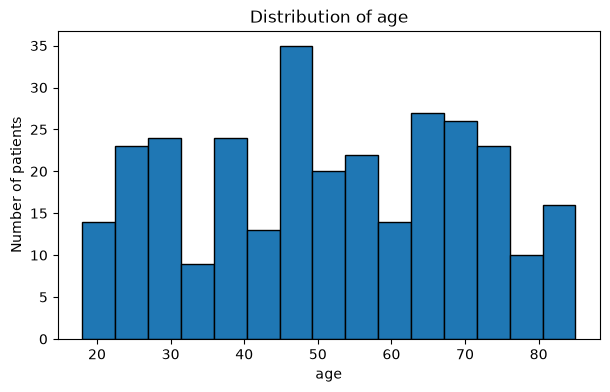

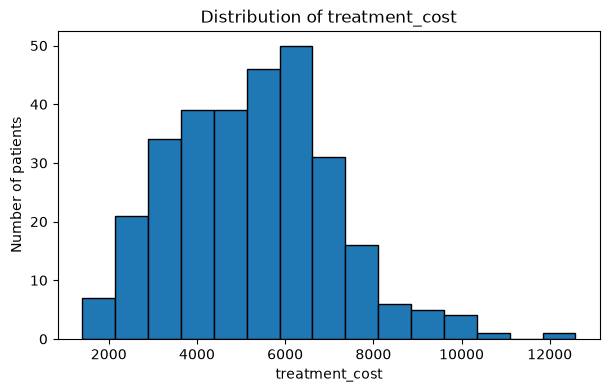

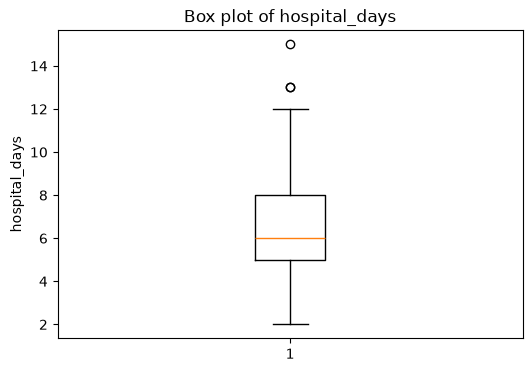

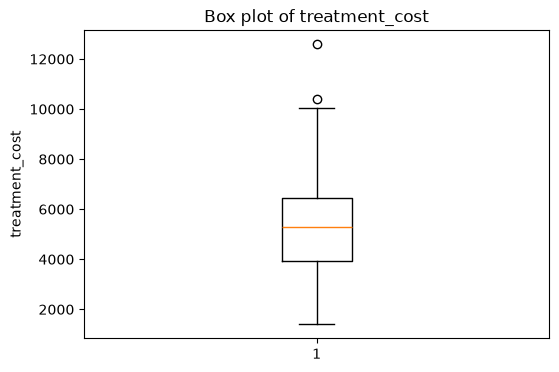

age IQR bounds: -10.88 114.12 | possible outliers: 0
bmi IQR bounds: 12.94 40.24 | possible outliers: 1
blood_pressure IQR bounds: 90.88 176.07 | possible outliers: 0
heart_rate IQR bounds: 48.59 96.09 | possible outliers: 4
hospital_days IQR bounds: 0.5 12.5 | possible outliers: 3
treatment_cost IQR bounds: 125.3 10248.03 | possible outliers: 2


In [4]:
for col in ["age", "treatment_cost"]:
    plt.figure(figsize=(7, 4))
    plt.hist(df[col], bins=15, edgecolor="black")
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Number of patients")
    plt.show()

for col in ["hospital_days", "treatment_cost"]:
    plt.figure(figsize=(6, 4))
    plt.boxplot(df[col])
    plt.title(f"Box plot of {col}")
    plt.ylabel(col)
    plt.show()

for col in variables:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5*iqr, q3 + 1.5*iqr
    count = ((df[col] < lower) | (df[col] > upper)).sum()
    print(col, "IQR bounds:", round(lower, 2), round(upper, 2), "| possible outliers:", count)

## Probability analysis

In [5]:
probabilities = {
    "Smoker": (df["smoker"] == "Yes").mean(),
    "Hospital stay > 5 days": (df["hospital_days"] > 5).mean(),
    "Diabetes": (df["diabetes"] == "Yes").mean(),
    "Follow-up required": (df["follow_up"] == "Yes").mean(),
    "BMI > 30": (df["bmi"] > 30).mean()
}
for event, probability in probabilities.items():
    print(f"P({event}) = {probability:.3f} = {probability:.1%}")

P(Smoker) = 0.247 = 24.7%
P(Hospital stay > 5 days) = 0.627 = 62.7%
P(Diabetes) = 0.120 = 12.0%
P(Follow-up required) = 0.460 = 46.0%
P(BMI > 30) = 0.243 = 24.3%


## Hypothesis testing

In [6]:
# Research question: Do patients requiring follow-up have a different mean hospital stay?
# H0: Mean hospital stay is equal in the follow-up and no-follow-up groups.
# Ha: Mean hospital stay differs between the two groups.
follow_yes = df.loc[df["follow_up"] == "Yes", "hospital_days"]
follow_no = df.loc[df["follow_up"] == "No", "hospital_days"]

# Welch's independent-samples t-test does not assume equal group variances.
t_stat, p_value = stats.ttest_ind(follow_yes, follow_no, equal_var=False)
alpha = 0.05
print("Follow-up group mean:", follow_yes.mean())
print("No-follow-up group mean:", follow_no.mean())
print("t statistic:", t_stat)
print("p-value:", p_value)
print("Decision:", "Reject H0" if p_value < alpha else "Fail to reject H0")

Follow-up group mean: 6.840579710144928
No-follow-up group mean: 5.679012345679013
t statistic: 4.494273114067828
p-value: 1.032076356070072e-05
Decision: Reject H0


## 95% confidence interval

In [7]:
cost = df["treatment_cost"]
mean_cost = cost.mean()
standard_error = stats.sem(cost)
ci_low, ci_high = stats.t.interval(
    confidence=0.95, df=len(cost)-1, loc=mean_cost, scale=standard_error
)
print("Sample mean:", mean_cost)
print("95% confidence interval:", (ci_low, ci_high))

Sample mean: 5286.716699999999
95% confidence interval: (np.float64(5080.14740139241), np.float64(5493.285998607588))


## Correlation analysis

,age,bmi,blood_pressure,heart_rate,hospital_days,treatment_cost
age,1.000,0.127,0.667,0.012,0.702,0.736
bmi,0.127,1.000,0.341,0.202,0.237,0.211
blood_pressure,0.667,0.341,1.000,0.044,0.651,0.640
heart_rate,0.012,0.202,0.044,1.000,-0.003,-0.008
hospital_days,0.702,0.237,0.651,-0.003,1.000,0.926
treatment_cost,0.736,0.211,0.640,-0.008,0.926,1.000


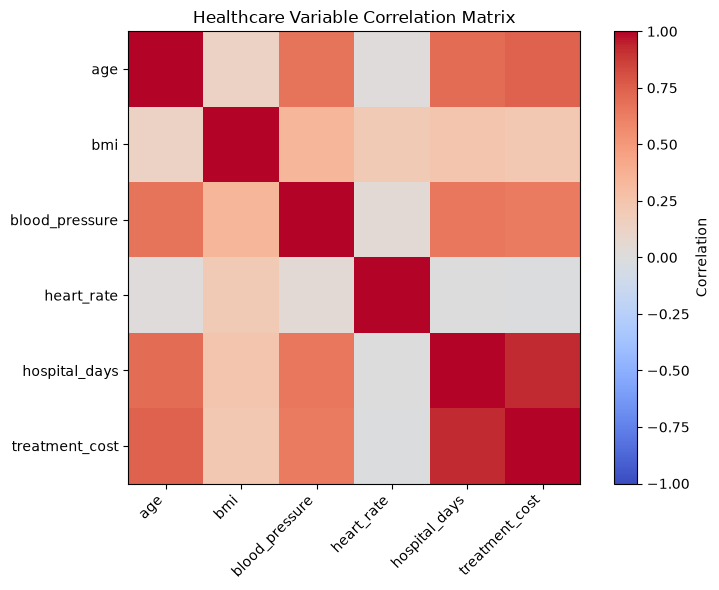

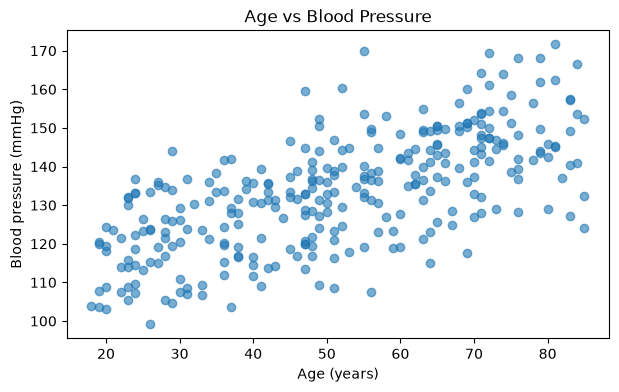

Age/blood pressure correlation: 0.6670659573116564
Hospital days/treatment cost correlation: 0.9256705784762771


In [8]:
corr = df[variables].corr(numeric_only=True)
display(corr.round(3))
plt.figure(figsize=(8, 6))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(variables)), variables, rotation=45, ha="right")
plt.yticks(range(len(variables)), variables)
plt.title("Healthcare Variable Correlation Matrix")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
plt.scatter(df["age"], df["blood_pressure"], alpha=0.6)
plt.title("Age vs Blood Pressure")
plt.xlabel("Age (years)")
plt.ylabel("Blood pressure (mmHg)")
plt.show()

print("Age/blood pressure correlation:", df["age"].corr(df["blood_pressure"]))
print("Hospital days/treatment cost correlation:", df["hospital_days"].corr(df["treatment_cost"]))

## Linear regression

Intercept: 748.8544247069658
Slope: 729.273616869378
Equation: predicted cost = 748.85 + 729.27 × hospital_days
R-squared: 0.8666537519851968
RMSE: 647.7143072696124
Prediction for 4 hospital days: 3665.9488921844777


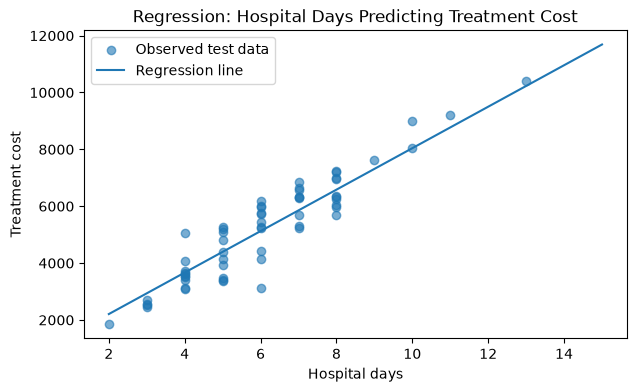

In [9]:
X = df[["hospital_days"]]
y = df["treatment_cost"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
model = LinearRegression()
model.fit(X_train, y_train)
predictions = model.predict(X_test)
r2 = r2_score(y_test, predictions)
rmse = mean_squared_error(y_test, predictions) ** 0.5

print("Intercept:", model.intercept_)
print("Slope:", model.coef_[0])
print(f"Equation: predicted cost = {model.intercept_:.2f} + {model.coef_[0]:.2f} × hospital_days")
print("R-squared:", r2)
print("RMSE:", rmse)
print("Prediction for 4 hospital days:", model.predict(pd.DataFrame({"hospital_days": [4]}))[0])

plt.figure(figsize=(7, 4))
plt.scatter(X_test["hospital_days"], y_test, alpha=0.6, label="Observed test data")
line_x = np.linspace(X["hospital_days"].min(), X["hospital_days"].max(), 100)
plt.plot(line_x, model.predict(pd.DataFrame({"hospital_days": line_x})), label="Regression line")
plt.title("Regression: Hospital Days Predicting Treatment Cost")
plt.xlabel("Hospital days")
plt.ylabel("Treatment cost")
plt.legend()
plt.show()